# 02 — Aplicação na PNS: revisitando o K-Means do Projeto 2

No workflow KNIME (`mineracao_de_dados/`) o nó **SimpleKMeans (Weka 3.7)** foi usado com
**k = 7**, distância euclidiana do Weka, 500 iterações e semente 10, seguido de **t-SNE** e
**Scatter Plot**. Aqui reproduzimos essa ideia em Python e fazemos as perguntas que um
relatório precisa responder:

1. Como representar dados quase 100% categóricos? (padronização/codificação)
2. k = 7 se justifica?
3. K-Means em one-hot × K-Modes: os resultados concordam?
4. Os clusters são estáveis?
5. **O que cada cluster significa?** (perfil)
6. Como visualizar sem se enganar (PCA × t-SNE)?

Teoria de apoio: [05_categoricos.md](05_categoricos.md), [06_avaliacao.md](06_avaliacao.md), [07_visualizacao.md](07_visualizacao.md).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, MinMaxScaler,
                                   StandardScaler, FunctionTransformer)
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from kmodes.kmodes import KModes

from utils.pns import carregar_pns, ordinais_presentes, NUMERICOS, ALVO
from utils.graficos import dispersao_clusters, curva_escolha_k, cores

plt.rcParams["figure.dpi"] = 90
SEMENTE = 10          # mesma semente do nó SimpleKMeans no KNIME
N_AMOSTRA = 5000      # para métricas O(n²) como a silhueta

## 1. Dados

Removemos colunas constantes e tiramos o alvo `Q00201` (diagnóstico de hipertensão) do agrupamento —
ele será usado só **depois**, para interpretar os grupos.

> ⚠️ No KNIME, confira no nó *Column Filter* se `Q00201` entrou no K-Means. Se entrou, os clusters
> já "conhecem" o alvo e não podem ser usados para descobrir relação com ele.

In [2]:
pns = carregar_pns()
alvo = pns[ALVO]
atributos = pns.drop(columns=[ALVO])

ordinais = ordinais_presentes(atributos)
nominais = [c for c in atributos.columns if c not in ordinais and c not in NUMERICOS]
print(f"{len(atributos)} linhas | {len(NUMERICOS)} numérico | {len(ordinais)} ordinais | {len(nominais)} nominais")
print("\nDistribuição do alvo (só para interpretação):")
print(alvo.value_counts(normalize=True).round(3))

53630 linhas | 1 numérico | 8 ordinais | 14 nominais

Distribuição do alvo (só para interpretação):
Q00201
Nao    0.616
Sim    0.384
Name: proportion, dtype: float64


## 2. Duas representações

| | **A — "estilo Weka"** | **B — proposta** |
|---|---|---|
| `C001` (numérico) | min-max [0,1] | log1p + z-score |
| ordinais | tratados como nominais (one-hot) | posição em [0,1] respeitando a ordem |
| nominais | one-hot | one-hot |

A representação A aproxima o que a `EuclideanDistance` do Weka faz (min-max nos numéricos e
diferença 0/1 nos nominais). A B é a construída no notebook de [padronização](../01_padronizacao/padronizacao.ipynb).

In [3]:
oh = lambda: OneHotEncoder(sparse_output=False, handle_unknown="ignore")

pre_A = ColumnTransformer([
    ("num", MinMaxScaler(), NUMERICOS),
    ("cat", oh(), list(ordinais) + nominais),
])
pre_B = ColumnTransformer([
    ("num", make_pipeline(FunctionTransformer(np.log1p, feature_names_out="one-to-one"), StandardScaler()), NUMERICOS),
    ("ord", make_pipeline(OrdinalEncoder(categories=list(ordinais.values())), MinMaxScaler()), list(ordinais)),
    ("nom", oh(), nominais),
])
XA = pre_A.fit_transform(atributos)
XB = pre_B.fit_transform(atributos)
print("A:", XA.shape, "  B:", XB.shape)

rng = np.random.default_rng(0)
idx_amostra = rng.choice(len(atributos), N_AMOSTRA, replace=False)

A: (53630, 80)   B: (53630, 45)


## 3. Reproduzindo o Projeto 2: K-Means com k = 7 (representação A)

In [4]:
km7_A = KMeans(7, n_init=10, max_iter=500, random_state=SEMENTE).fit(XA)
rot_km7_A = km7_A.labels_
print("Tamanho dos clusters:", np.bincount(rot_km7_A))
print(f"Silhueta (amostra de {N_AMOSTRA}): {silhouette_score(XA[idx_amostra], rot_km7_A[idx_amostra]):.3f}")

Tamanho dos clusters: [8210 7384 8248 7239 7372 6037 9140]


Silhueta (amostra de 5000): 0.047


## 4. k = 7 se justifica? Cotovelo e silhueta (K-Means, representação B)

k,2,3,4,5,6,7,8,9,10
silhueta,0.096,0.087,0.082,0.071,0.069,0.069,0.071,0.069,0.069


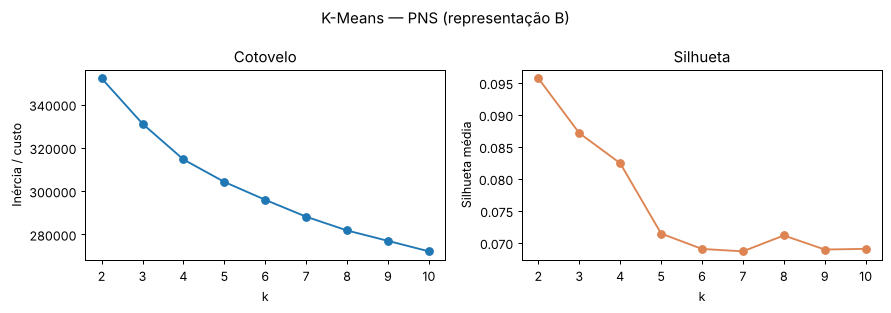

In [5]:
ks = list(range(2, 11))
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(k, n_init=5, random_state=SEMENTE).fit(XB)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(XB[idx_amostra], km.labels_[idx_amostra]))
curva_escolha_k(ks, inercias, silhuetas, "K-Means — PNS (representação B)")
pd.DataFrame({"k": ks, "silhueta": np.round(silhuetas, 3)}).set_index("k").T

**Como ler:** silhuetas abaixo de ~0,25 indicam que **não há estrutura de grupos forte** — os
clusters são mais uma *partição útil* do que grupos naturais. Isso é comum em dados de
questionário e precisa ser dito no relatório.

## 5. K-Modes: a alternativa feita para dados categóricos

Usamos todos os atributos como categorias (inclusive `C001`, agrupado em faixas).
A métrica de custo é a soma das distâncias de Hamming.

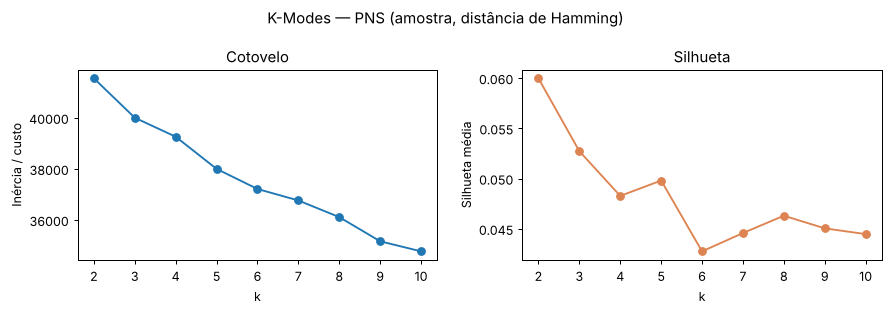

In [6]:
cat = atributos.copy()
cat["C001"] = pd.cut(cat["C001"], [0, 1, 2, 3, 4, 100], labels=["1", "2", "3", "4", "5+"]).astype(str)
cat = cat.astype(str)

amostra_cat = cat.iloc[idx_amostra]
cat_codificado = OrdinalEncoder().fit_transform(cat)  # inteiros só para calcular Hamming (não é ordem!)

custos, silh_hamming = [], []
for k in ks:
    kmo = KModes(k, init="Cao", n_init=1, random_state=SEMENTE).fit(amostra_cat)
    custos.append(kmo.cost_)
    silh_hamming.append(silhouette_score(cat_codificado[idx_amostra], kmo.labels_, metric="hamming"))
curva_escolha_k(ks, custos, silh_hamming, "K-Modes — PNS (amostra, distância de Hamming)");

## 6. Estabilidade: os grupos se repetem com outras sementes?

Para cada configuração rodamos 5 sementes e calculamos o ARI entre todos os pares.
ARI perto de 1 = sempre os mesmos grupos; perto de 0 = grupos mudam a cada execução.

In [7]:
from itertools import combinations

def estabilidade(ajustar, sementes=(0, 1, 2, 3, 4)):
    rotulos = [ajustar(s) for s in sementes]
    return np.mean([adjusted_rand_score(a, b) for a, b in combinations(rotulos, 2)])

K_ESCOLHIDO = ks[int(np.argmax(silhuetas))]
print("k com maior silhueta (K-Means B):", K_ESCOLHIDO)

configs = {
    "K-Means A, k=7": lambda s: KMeans(7, n_init=1, random_state=s).fit_predict(XA[idx_amostra]),
    "K-Means B, k=7": lambda s: KMeans(7, n_init=1, random_state=s).fit_predict(XB[idx_amostra]),
    f"K-Means B, k={K_ESCOLHIDO}": lambda s: KMeans(K_ESCOLHIDO, n_init=1, random_state=s).fit_predict(XB[idx_amostra]),
    # init "Cao" é determinística (daria ARI = 1 trivialmente); "Huang" sorteia os modos iniciais
    "K-Modes (init Huang), k=7": lambda s: KModes(7, init="Huang", n_init=1, random_state=s).fit_predict(amostra_cat),
}
pd.Series({nome: estabilidade(f) for nome, f in configs.items()}, name="ARI médio entre sementes").round(3).to_frame()

k com maior silhueta (K-Means B): 2


,ARI médio entre sementes
"K-Means A, k=7",0.479
"K-Means B, k=7",0.397
"K-Means B, k=2",0.874
"K-Modes (init Huang), k=7",0.111


## 7. As representações concordam entre si?

In [8]:
rot_km7_B = KMeans(7, n_init=10, random_state=SEMENTE).fit_predict(XB)
kmo7 = KModes(7, init="Cao", n_init=1, random_state=SEMENTE).fit(cat)
rot_kmo7 = kmo7.labels_

pares = {"K-Means A × K-Means B": (rot_km7_A, rot_km7_B),
         "K-Means A × K-Modes": (rot_km7_A, rot_kmo7),
         "K-Means B × K-Modes": (rot_km7_B, rot_kmo7)}
pd.Series({n: adjusted_rand_score(a, b) for n, (a, b) in pares.items()}, name="ARI (k=7)").round(3).to_frame()

,ARI (k=7)
K-Means A × K-Means B,0.362
K-Means A × K-Modes,0.165
K-Means B × K-Modes,0.163


ARIs baixos aqui significam que **a escolha da representação muda os grupos encontrados** —
mais um motivo para justificar o pré-processamento no relatório.

## 8. Perfil dos clusters (o passo mais importante)

Os centróides do K-Modes são combinações reais de categorias — fáceis de ler.
Acrescentamos o tamanho de cada grupo e a **taxa de hipertensão** (`Q00201 = Sim`), que não foi usada no agrupamento.

In [9]:
perfil = pd.DataFrame(kmo7.cluster_centroids_, columns=cat.columns)
perfil.insert(0, "tamanho", np.bincount(rot_kmo7))
perfil.insert(1, "% hipertensão", (pd.crosstab(rot_kmo7, alvo, normalize="index")["Sim"] * 100).round(1).values)
perfil.T

,0,1,2,3,4,5,6
tamanho,24790,5674,8419,3191,3592,6102,1862
% hipertensão,46.6,32.5,28.2,33.7,43.3,20.6,48.6
A001,Casa,Casa,Casa,Casa,Casa,Casa,Casa
C001,2,1,3,4,1,3,2
C006,Mulher,Homem,Homem,Mulher,Homem,Homem,Mulher
C008,60-69 anos,50-59 anos,39-49 anos,50-59 anos,50-59 anos,39-49 anos,60-69 anos
C009,Parda,Branca,Branca,Parda,Parda,Parda,Branca
C011,Casado,Solteiro,Casado,Solteiro,Solteiro,Solteiro,Divorciado/separado
D001,Sim,Sim,Sim,Sim,Sim,Sim,Sim
M005010,Sem resposta,Nao,Nao,Nao,Nao,Nao,Nao


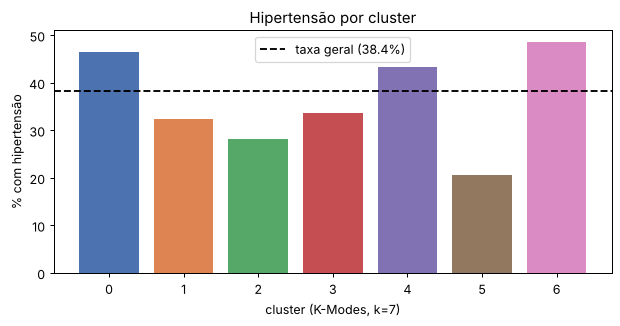

In [10]:
taxa_geral = (alvo == "Sim").mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.5))
taxas = perfil["% hipertensão"]
ax.bar(taxas.index.astype(str), taxas, color=cores(taxas.index))
ax.axhline(taxa_geral, ls="--", c="k", label=f"taxa geral ({taxa_geral:.1f}%)")
ax.set(xlabel="cluster (K-Modes, k=7)", ylabel="% com hipertensão", title="Hipertensão por cluster")
ax.legend();

**Perguntas para interpretar:** que atributos mudam de um cluster para o outro (faixa etária?
escolaridade? hábitos)? Os clusters com taxa de hipertensão acima da média têm algo em comum?
Dê um **nome** a cada cluster — se não conseguir, talvez *k* esteja alto demais.

## 9. Visualização: PCA × t-SNE

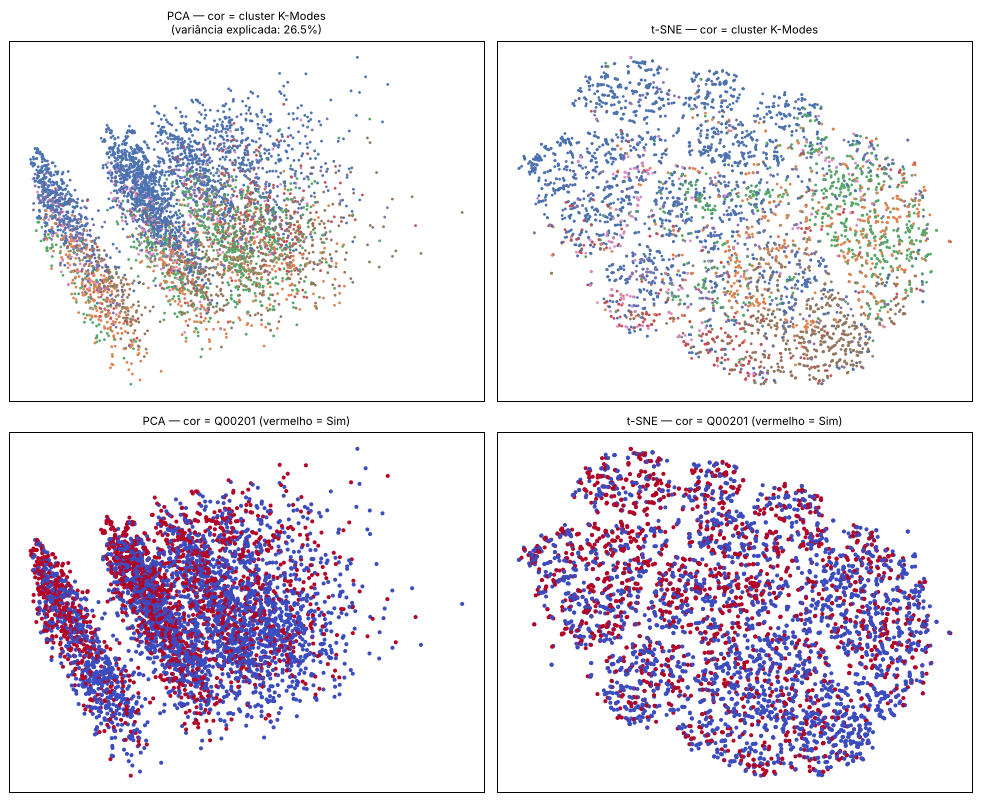

In [11]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA(2, random_state=0).fit(XB)
P = pca.transform(XB[idx_amostra])
T = TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(XB[idx_amostra])
alvo_amostra = (alvo.iloc[idx_amostra] == "Sim").astype(int).to_numpy()
rot_amostra = rot_kmo7[idx_amostra]

fig, axs = plt.subplots(2, 2, figsize=(11, 9))
dispersao_clusters(axs[0, 0], P, rot_amostra, f"PCA — cor = cluster K-Modes\n(variância explicada: {pca.explained_variance_ratio_.sum():.1%})", s=5)
dispersao_clusters(axs[0, 1], T, rot_amostra, "t-SNE — cor = cluster K-Modes", s=5)
for ax, Z, nome in [(axs[1, 0], P, "PCA"), (axs[1, 1], T, "t-SNE")]:
    ax.scatter(Z[:, 0], Z[:, 1], c=alvo_amostra, cmap="coolwarm", s=5)
    ax.set_title(f"{nome} — cor = Q00201 (vermelho = Sim)", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()

Lembre (ver [07_visualizacao.md](07_visualizacao.md)): no t-SNE, tamanhos e distâncias entre
"ilhas" **não têm significado**; a PCA mostra só a fração de variância indicada no título.

## 10. O que a execução de referência mostrou

Os números abaixo vêm da execução salva neste notebook (sementes fixas); se você mudar algo, eles mudam.

- **Estrutura fraca:** silhueta de 0,047 no K-Means k=7 (representação A) e no máximo 0,096 (k=2, representação B).
  Valores tão baixos indicam que a PNS **não forma grupos naturais bem separados**.
- **k = 7 não é sustentado** pelas métricas internas; a silhueta cai de forma quase contínua com *k*, sem cotovelo nítido.
- **Instabilidade:** com k=7, o ARI entre sementes fica em ~0,40–0,48 (K-Means) e ~0,11 (K-Modes);
  com k=2 sobe para ~0,87.
- **Representação importa:** A × B × K-Modes concordam pouco (ARI 0,16–0,36).
- **Ainda assim há sinal útil:** a taxa de hipertensão varia de ~21% a ~49% entre os clusters do K-Modes
  (média geral 38%), acompanhando principalmente a faixa etária.

**Conclusão honesta para o relatório:** os clusters funcionam como uma **segmentação** útil para descrever
perfis, não como "tipos" naturais de pessoas. Isso não é um fracasso — é um resultado, e reportá-lo
com as métricas é o que torna o trabalho metodologicamente sólido.

## 11. Checklist para o relatório do Projeto 2

- [ ] Explicar como cada tipo de atributo foi representado (e por quê).
- [ ] Remover/justificar colunas constantes e a coluna alvo.
- [ ] Mostrar cotovelo + silhueta (ou custo do K-Modes) para justificar *k*.
- [ ] Relatar a silhueta e interpretar honestamente a força da estrutura.
- [ ] Relatar estabilidade entre sementes.
- [ ] Perfilar e nomear os clusters; relacionar com `Q00201` só **depois**.
- [ ] Usar t-SNE como ilustração, não como prova.
- [ ] Registrar o uso de IA (ver [`../REGISTRO_USO_IA.md`](../REGISTRO_USO_IA.md)).

## 12. Exercícios

1. Inclua `Q00201` como atributo no K-Modes e compare o perfil. O que muda e por que isso é um problema metodológico?
2. Rode o K-Prototypes (`kmodes.kprototypes.KPrototypes`) mantendo `C001` numérico. Varie `gamma`.
3. Use a distância de Gower em uma amostra de 2.000 linhas com `AgglomerativeClustering(metric="precomputed", linkage="average")` e compare com o K-Modes via ARI.
4. Rode o HDBSCAN na matriz `XB` (amostra). Ele encontra grupos densos ou classifica quase tudo como ruído? O que isso diz sobre os dados?
5. Com k=2 (o mais estável), descubra quais atributos mais diferem entre os dois grupos.
6. No KNIME, troque o SimpleKMeans por **k-Medoids** ou ative o nó **Normalizer** antes dele e compare os tamanhos de cluster.